## **Titanic Visualizations**

In [2]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Download latest version
path = kagglehub.dataset_download("yasserh/titanic-dataset")

print("Path to dataset files:", path)

100%|██████████| 22.0k/22.0k [00:00<00:00, 22.9MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/yasserh/titanic-dataset/versions/1


In [4]:
df = pd.read_csv(path+"/Titanic-Dataset.csv")

#count non-mssing values in each column
df.count()

,0
PassengerId,891
Survived,891
Pclass,891
Name,891
Sex,891
Age,714
SibSp,891
Parch,891
Ticket,891
Fare,891


Age visualization:
Histogram, Box plot (to see the median and outliers), KDE plot (density plot of the histogram - without spikes)

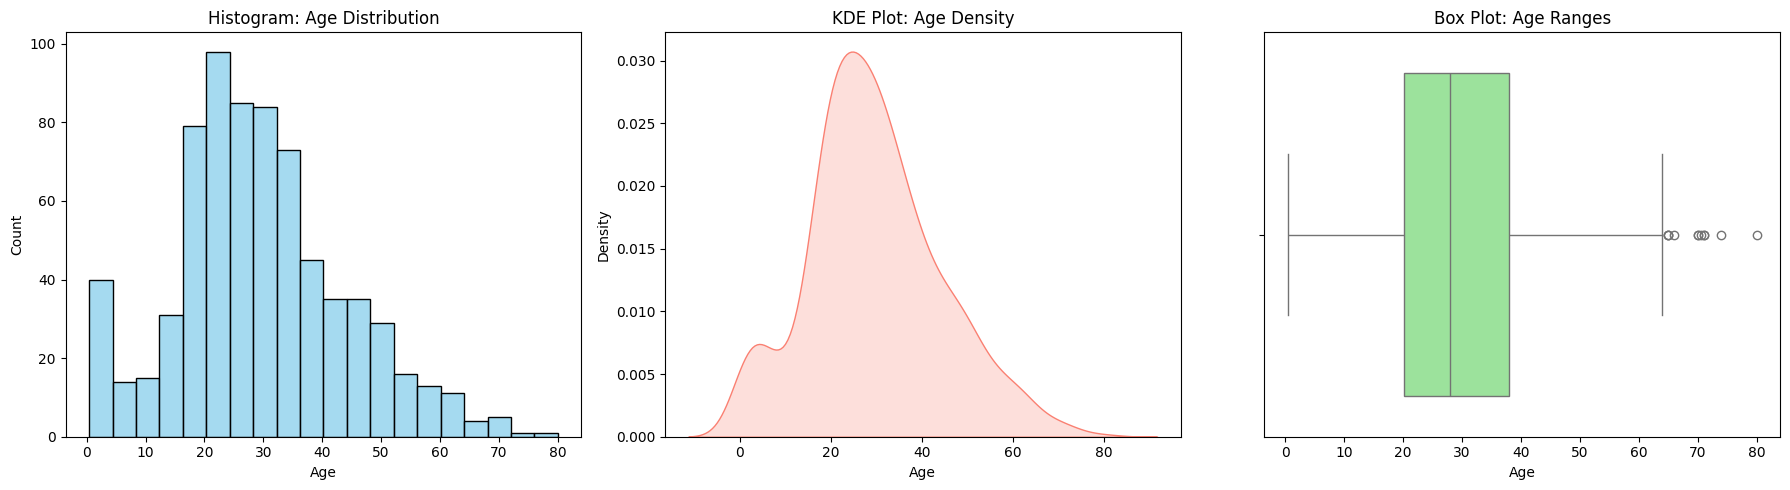

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df['Age'], bins=20, ax=axes[0], color='skyblue')
axes[0].set_title('Histogram: Age Distribution')

sns.kdeplot(df['Age'], fill=True, ax=axes[1], color='salmon')
axes[1].set_title('KDE Plot: Age Density')

sns.boxplot(x=df['Age'], ax=axes[2], color='lightgreen')
axes[2].set_title('Box Plot: Age Ranges')

plt.tight_layout()
plt.show()

Males tend to be older. There are more more males (n=577) than females (n=314) as the male distribution is similar to the overall distribution. Histogram and KDE plots seems to be problematic since the males and females overlap. Violin plot seems to be the best as it shows non-overlapping distributions.

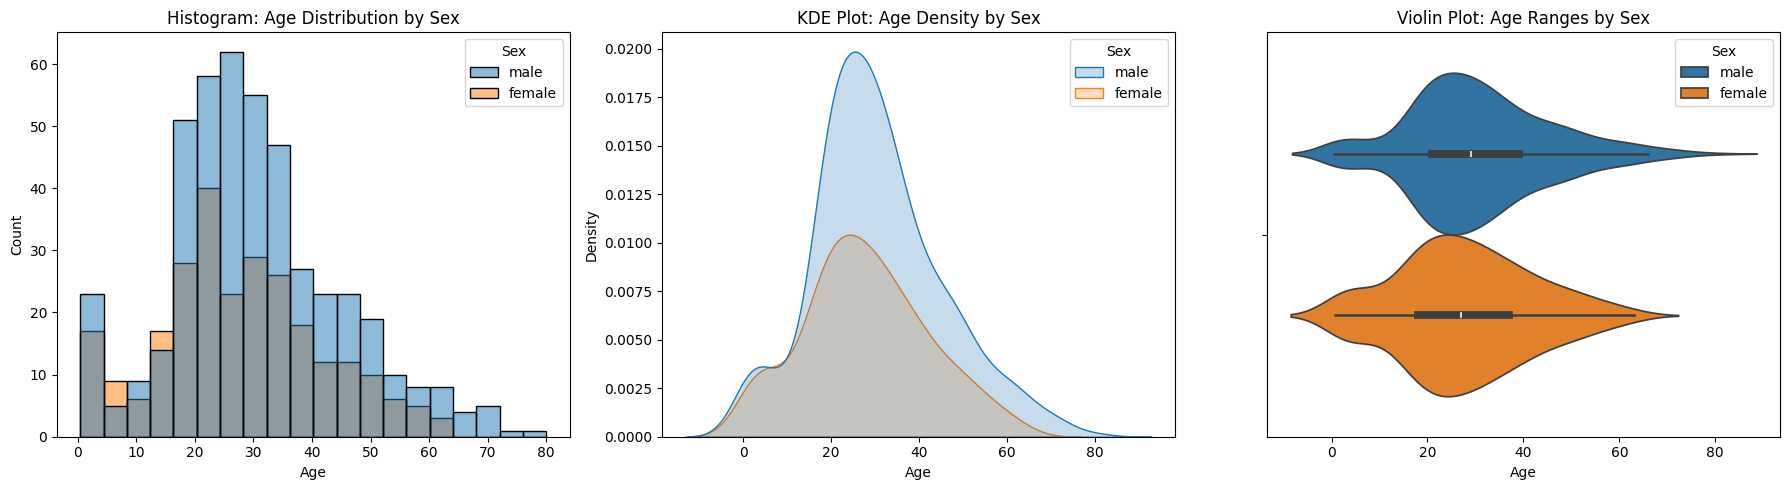

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(data=df, x='Age', hue='Sex', bins=20, ax=axes[0])
axes[0].set_title('Histogram: Age Distribution by Sex')

sns.kdeplot(data=df, x='Age', hue='Sex', fill=True, ax=axes[1])
axes[1].set_title('KDE Plot: Age Density by Sex')

sns.violinplot(data=df, x='Age', hue='Sex', ax=axes[2])
axes[2].set_title('Violin Plot: Age Ranges by Sex')

plt.tight_layout()
plt.show()

Mean survival rate categorized by sex and passenger class. Heatmap only shows one value per subgroup of age. Bar chart is a great visualization as it shows the clear difference based on sex and class.

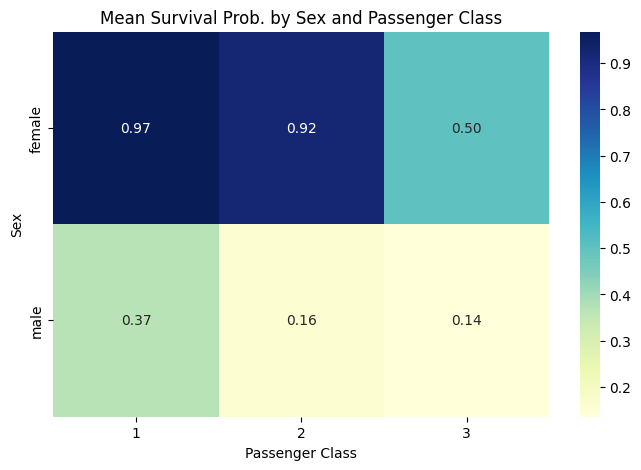

In [11]:
survival_pivot = df.pivot_table(values='Survived', index='Sex', columns='Pclass', aggfunc='mean')

plt.figure(figsize=(8, 5))
sns.heatmap(survival_pivot, annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("Mean Survival Prob. by Sex and Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Sex")
plt.show()

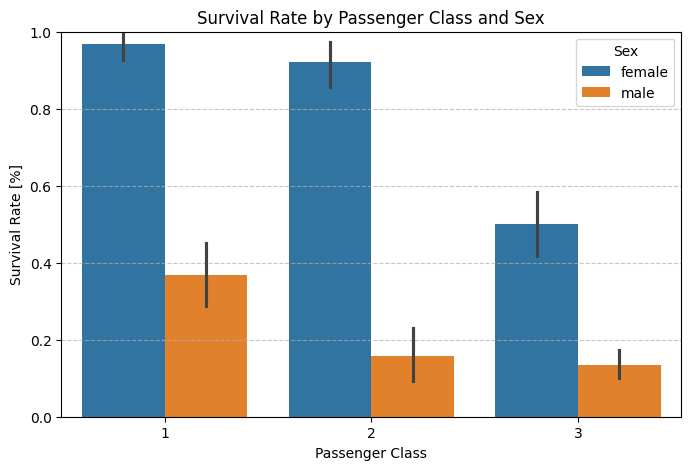

In [45]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='Pclass', y='Survived', hue='Sex')
plt.title("Survival Rate by Passenger Class and Sex")
plt.ylabel("Survival Rate [%]")
plt.xlabel("Passenger Class")
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

Additional stories. Survived people are clearly distinguishable by Age and Class (boxplot).  

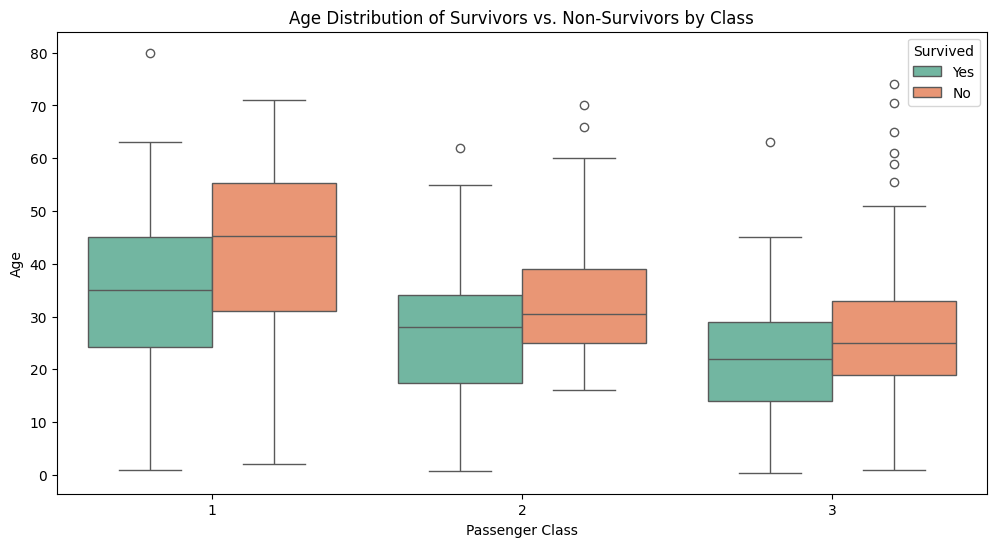

In [40]:
plt.figure(figsize=(12, 6))

new_labels = {0: 'No', 1: 'Yes'}
df['Survived_legend'] = df['Survived'].map(new_labels)

sns.boxplot(data=df, x='Pclass', y='Age', hue='Survived_legend', palette='Set2')

plt.title("Age Distribution of Survivors vs. Non-Survivors by Class")
plt.xlabel("Passenger Class")
plt.ylabel("Age")
plt.legend(title="Survived")
plt.show()


Scatter plot of Age vs. Fare colored by Survival. High income people seems to have a higher chance to survive.

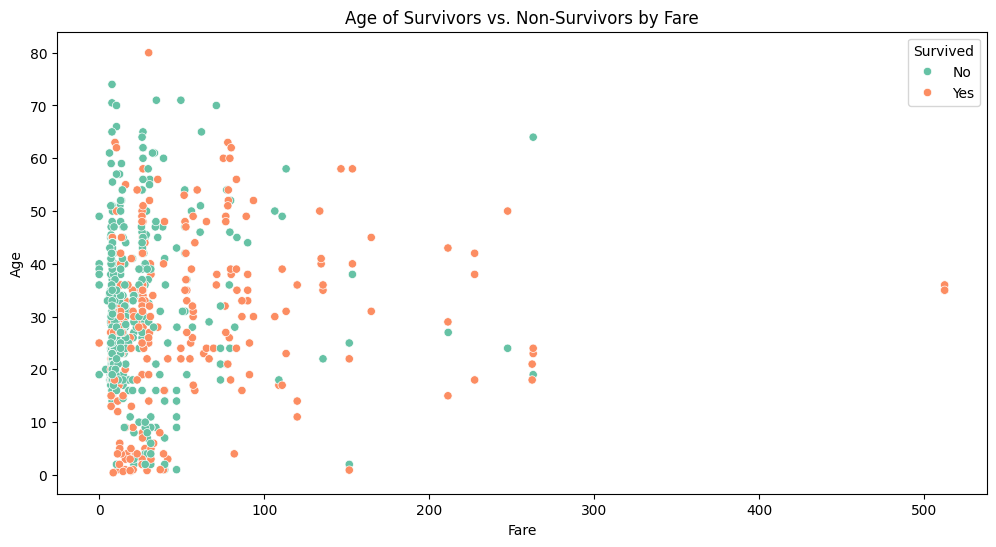

In [47]:
plt.figure(figsize=(12, 6))

new_labels = {0: 'No', 1: 'Yes'}
df['Survived_legend'] = df['Survived'].map(new_labels)

sns.scatterplot(data=df, x='Fare', y='Age', hue='Survived_legend', palette='Set2')

plt.title("Age of Survivors vs. Non-Survivors by Fare")
plt.xlabel("Fare")
plt.ylabel("Age")
plt.legend(title="Survived")
plt.show()

If the person had 1-2 parents/childrens then he was more likely to survive

/tmp/ipython-input-386860254.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Parch', y='Survived', palette='viridis', capsize=.1)


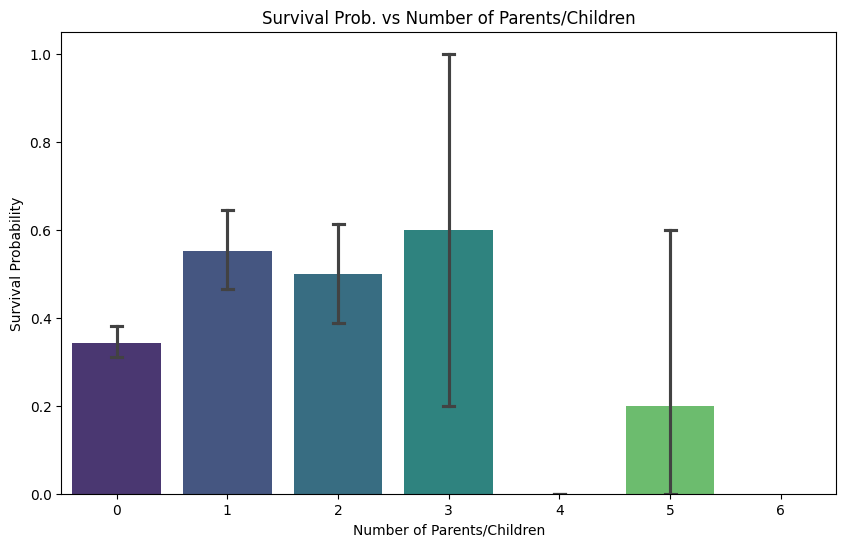

In [10]:
plt.figure(figsize=(10, 6))
sns.barplot(data=df, x='Parch', y='Survived', palette='viridis', capsize=.1)

plt.title('Survival Prob. vs Number of Parents/Children')
plt.xlabel('Number of Parents/Children')
plt.ylabel('Survival Probability')
plt.show()

Seems like if the person embarked from Southampton and was in the third class, he was less likely to survive comapred to other port locations

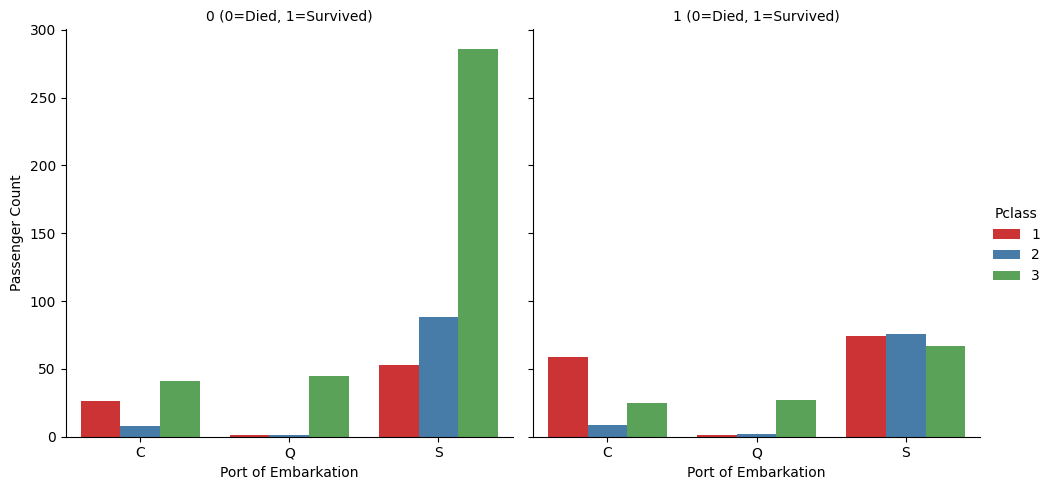

In [9]:
g = sns.catplot(
    data=df, x="Embarked", hue="Pclass", col="Survived",
    kind="count", palette="Set1", order=['C', 'Q', 'S']
)

g.set_axis_labels("Port of Embarkation", "Passenger Count")
g.set_titles("{col_name} (0=Died, 1=Survived)")
plt.show()